Périphérique utilisé : cuda


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.35MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 131kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.28MB/s]


Nombre d'images        : 60000
Forme d'un batch       : torch.Size([128, 1, 28, 28])
Intervalle des pixels  : -1.0 à 1.0


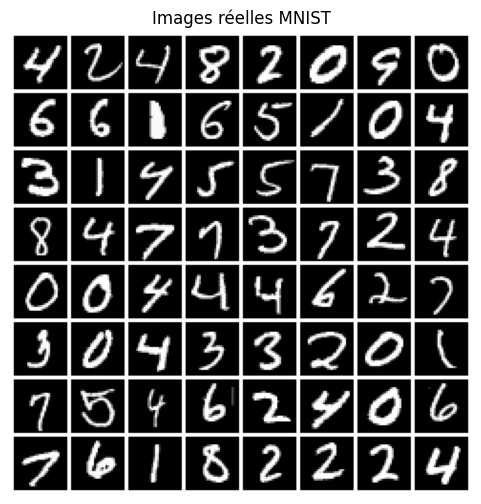

In [1]:
# =====================================================
# TP 4 — StyleGAN : génération d'images, styles latents et contrôle de la synthèse
# =====================================================

# =====================================================
# Partie A — Question 1 : du GAN classique à StyleGAN
# =====================================================
# a) GAN classique G(z) : le vecteur z ~ N(0, I) est donné uniquement à l'entrée du générateur, puis
#    transformé couche après couche jusqu'à l'image. Toute l'information (forme, style, détails) doit être
#    contenue dans z dès le départ : les facteurs de variation sont « intriqués ».
# b) Générateur style-based : z passe d'abord par un réseau de mapping (MLP) qui donne w = f(z). Le réseau
#    de synthèse part d'une constante apprise, et w est injecté à CHAQUE couche via une normalisation
#    adaptative (AdaIN) qui règle l'échelle et le biais des cartes de caractéristiques. Les couches de basse
#    résolution contrôlent les attributs grossiers (forme, pose), celles de haute résolution les détails fins.
#    Un bruit aléatoire est ajouté à chaque couche pour les détails stochastiques.
# c) Z est l'espace d'échantillonnage, de loi imposée (gaussienne) : le générateur doit le « tordre » pour
#    l'adapter aux données, ce qui intrique les attributs. W est appris par le réseau de mapping et n'a pas
#    de loi imposée : il peut « déplier » l'espace, si bien que ses directions correspondent mieux à des
#    attributs indépendants. W est plus « démêlé » : interpolations plus régulières, meilleur contrôle.

# =====================================================
# Partie A — Question 2 : éthique et usages responsables
# =====================================================
# Usages positifs : (1) données synthétiques pour augmenter des jeux de données rares ou sensibles
# (imagerie médicale) en protégeant la vie privée ; (2) création et design (personnages, textures, objets)
# et outil pédagogique pour comprendre les modèles génératifs.
# Risques : (1) désinformation et usurpation d'identité (faux profils, hypertrucages / deepfakes, fraude) ;
# (2) images non consenties de personnes réelles et reproduction des biais des données d'entraînement.
# Bonnes pratiques : (1) utiliser des jeux de données publics et non sensibles (MNIST, Fashion-MNIST), sans
# photos de personnes sans leur consentement ; (2) indiquer clairement que les images sont synthétiques et
# ne pas les diffuser hors du cadre du TP ; (3) documenter les limites et les biais du modèle.

# =====================================================
# Partie B — Question 3 : configuration du périphérique (mps, cuda ou cpu)
# =====================================================
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import numpy as np
import matplotlib.pyplot as plt

def choisir_peripherique():
    if torch.backends.mps.is_available():        # a) Apple Silicon
        return torch.device("mps")
    if torch.cuda.is_available():                # b) GPU NVIDIA
        return torch.device("cuda")
    return torch.device("cpu")                   # c) sinon, processeur

device = choisir_peripherique()
print("Périphérique utilisé :", device)

# =====================================================
# Partie B — Question 4 : chargement des données (MNIST)
# =====================================================
transform = transforms.Compose([
    transforms.ToTensor(),                       # pixels entre 0 et 1
    transforms.Normalize((0.5,), (0.5,)),        # pixels entre -1 et 1 (le générateur finit par tanh)
])
dataset = torchvision.datasets.MNIST(root="./data", train=True, download=True, transform=transform)
loader = DataLoader(dataset, batch_size=128, shuffle=True, num_workers=0, drop_last=True)   # num_workers=0 (consigne)

x, y = next(iter(loader))
print("Nombre d'images        :", len(dataset))
print("Forme d'un batch       :", x.shape)
print("Intervalle des pixels  :", x.min().item(), "à", x.max().item())

grille = torchvision.utils.make_grid(x[:64], nrow=8, normalize=True, value_range=(-1, 1), pad_value=1)
plt.figure(figsize=(6, 6)); plt.imshow(grille.permute(1, 2, 0)); plt.axis("off")
plt.title("Images réelles MNIST"); plt.show()

In [2]:
# =====================================================
# Partie C — Question 5 : réseau de mapping f : z (R^dz) -> w (R^dw)
# =====================================================
z_dim, w_dim = 64, 64

class Mapping(nn.Module):
    def __init__(self, z_dim=z_dim, w_dim=w_dim, nb_couches=4):
        super().__init__()
        couches, dim = [], z_dim
        for _ in range(nb_couches):                     # z -> Linear -> LeakyReLU -> ... -> w
            couches += [nn.Linear(dim, w_dim), nn.LeakyReLU(0.2)]
            dim = w_dim
        self.reseau = nn.Sequential(*couches)
    def forward(self, z):
        z = z / torch.sqrt((z ** 2).mean(dim=1, keepdim=True) + 1e-8)   # normalisation de z (pixel norm)
        return self.reseau(z)

# Pourquoi normaliser z ? Pour que tous les codes aient la même norme : le réseau de mapping reçoit des entrées
# d'échelle stable (pas de valeurs extrêmes), ce qui stabilise l'apprentissage, et seule la DIRECTION de z
# compte (pour z ~ N(0, I), la norme varie peu de toute façon, et c'est la direction qui porte l'information).

# =====================================================
# Partie C — Question 6 : normalisation adaptative de style (AdaIN)
# AdaIN(x, w) = γ(w) · (x - μ(x)) / (σ(x) + ε) + β(w)
# =====================================================
class AdaIN(nn.Module):
    def __init__(self, canaux, w_dim=w_dim):
        super().__init__()
        self.canaux = canaux
        self.norm = nn.InstanceNorm2d(canaux, affine=False)    # (x - μ(x)) / (σ(x) + ε), par carte et par image
        self.style = nn.Linear(w_dim, 2 * canaux)              # w -> (γ, β) pour chaque carte
    def forward(self, x, w):
        s = self.style(w)
        gamma = 1 + s[:, :self.canaux, None, None]             # échelle γ(w) (centrée sur 1)
        beta = s[:, self.canaux:, None, None]                  # biais β(w)
        return gamma * self.norm(x) + beta

# Rôle de γ(w) et β(w) : la normalisation efface la moyenne et l'écart-type de chaque carte de
# caractéristiques ; γ(w) fixe ensuite son AMPLITUDE (importance de la caractéristique) et β(w) son
# NIVEAU moyen. Le style w décide donc, couche par couche, quelles caractéristiques sont renforcées ou
# atténuées : c'est ainsi que w « contrôle » l'image à chaque résolution.

# =====================================================
# Partie C — Question 7 : injection de bruit  x' = x + α η   (α appris par carte, η ~ N(0, 1) spatial)
# =====================================================
class InjectionBruit(nn.Module):
    def __init__(self, canaux):
        super().__init__()
        self.alpha = nn.Parameter(torch.full((1, canaux, 1, 1), 0.1))   # poids appris du bruit, par carte
    def forward(self, x, bruit=None):
        if bruit is None:
            bruit = torch.randn(x.size(0), 1, x.size(2), x.size(3), device=x.device)   # η : une valeur par pixel
        return x + self.alpha * bruit

# Ce bruit contrôle les détails STOCHASTIQUES et locaux, qui peuvent varier sans changer l'identité de
# l'image : texture, petites irrégularités du trait, épaisseur locale. (Sur des visages : cheveux, pores.)

# =====================================================
# Partie C — Question 8 : bloc de synthèse stylisé
# a) upsampling (option)  b) convolution  c) bruit  d) activation  e) AdaIN
# =====================================================
class BlocStyle(nn.Module):
    def __init__(self, c_in, c_out, upsample):
        super().__init__()
        self.upsample = nn.Upsample(scale_factor=2, mode="nearest") if upsample else nn.Identity()   # a)
        self.conv = nn.Conv2d(c_in, c_out, 3, padding=1)                                             # b)
        self.bruit = InjectionBruit(c_out)                                                           # c)
        self.act = nn.LeakyReLU(0.2)                                                                 # d)
        self.adain = AdaIN(c_out)                                                                    # e)
    def forward(self, x, w, bruit=None):
        x = self.conv(self.upsample(x))
        x = self.act(self.bruit(x, bruit))
        return self.adain(x, w)

# =====================================================
# Partie C — Question 9 : générateur Mini-StyleGAN
# a) constante apprise 7x7  b) blocs stylisés  c) image 1x28x28  d) un ou deux codes (style mixing)
# =====================================================
class MiniStyleGAN(nn.Module):
    def __init__(self):
        super().__init__()
        self.mapping = Mapping()
        self.constante = nn.Parameter(torch.randn(1, 128, 7, 7))             # a) constante apprise
        self.blocs = nn.ModuleList([                                          # b) blocs stylisés
            BlocStyle(128, 128, upsample=False),   # 7x7   : couche grossière
            BlocStyle(128, 64, upsample=True),     # 14x14 : couche grossière / moyenne
            BlocStyle(64, 32, upsample=True),      # 28x28 : couche fine
            BlocStyle(32, 32, upsample=False),     # 28x28 : couche fine
        ])
        self.vers_image = nn.Conv2d(32, 1, 1)                                 # c) 32 cartes -> 1 canal
        self.nb_styles = len(self.blocs)

    def synthese(self, ws, bruits=None):                   # ws : un w par bloc
        x = self.constante.expand(ws[0].size(0), -1, -1, -1)
        for k, bloc in enumerate(self.blocs):
            x = bloc(x, ws[k], None if bruits is None else bruits[k])
        return torch.tanh(self.vers_image(x))                                 # pixels entre -1 et 1

    def forward(self, z1, z2=None, croisement=2):          # d) style mixing avec un 2e code
        w1 = self.mapping(z1)
        if z2 is None:
            ws = [w1] * self.nb_styles
        else:                                               # couches grossières : w1 ; couches fines : w2
            w2 = self.mapping(z2)
            ws = [w1] * croisement + [w2] * (self.nb_styles - croisement)
        return self.synthese(ws)

# =====================================================
# Partie C — Question 10 : discriminateur convolutionnel (image 1x28x28 -> probabilité de réalisme)
# =====================================================
class Discriminateur(nn.Module):
    def __init__(self):
        super().__init__()
        self.reseau = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),                           # -> 64x14x14
            nn.Conv2d(64, 128, 4, 2, 1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),    # -> 128x7x7
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1), nn.Sigmoid())                  # -> probabilité
    def forward(self, x):
        return self.reseau(x)

# ---- Tests rapides (modèles non entraînés) ----
G_test, D_test = MiniStyleGAN().to(device), Discriminateur().to(device)
z1 = torch.randn(8, z_dim, device=device); z2 = torch.randn(8, z_dim, device=device)
print("Q5  : forme de w = f(z)                :", G_test.mapping(z1).shape)
xa = torch.randn(8, 32, 14, 14, device=device)
print("Q6  : forme de AdaIN(x, w)             :", AdaIN(32).to(device)(xa, G_test.mapping(z1)).shape)
print("Q7  : forme après injection de bruit   :", InjectionBruit(32).to(device)(xa).shape)
print("Q8  : bloc 128x7x7 -> (upsample)       :", BlocStyle(128, 64, True).to(device)(torch.randn(8, 128, 7, 7, device=device), G_test.mapping(z1)).shape)
img1, img2 = G_test(z1), G_test(z1, z2)
print("Q9  : image avec un code / deux codes  :", img1.shape, "/", img2.shape, "| pixels entre", round(img1.min().item(), 2), "et", round(img1.max().item(), 2))
p = D_test(img1)
print("Q10 : sortie du discriminateur         :", p.shape, "| valeurs entre", round(p.min().item(), 3), "et", round(p.max().item(), 3))
print("Paramètres : générateur =", sum(q.numel() for q in G_test.parameters()),
      "| discriminateur =", sum(q.numel() for q in D_test.parameters()))

Q5  : forme de w = f(z)                : torch.Size([8, 64])
Q6  : forme de AdaIN(x, w)             : torch.Size([8, 32, 14, 14])
Q7  : forme après injection de bruit   : torch.Size([8, 32, 14, 14])
Q8  : bloc 128x7x7 -> (upsample)       : torch.Size([8, 64, 14, 14])
Q9  : image avec un code / deux codes  : torch.Size([8, 1, 28, 28]) / torch.Size([8, 1, 28, 28]) | pixels entre -0.96 et 0.98
Q10 : sortie du discriminateur         : torch.Size([8, 1]) | valeurs entre 0.631 et 0.798
Paramètres : générateur = 305569 | discriminateur = 138817


Époque  1/10 | loss_D = 1.227 | loss_G = 1.537 | 23 s


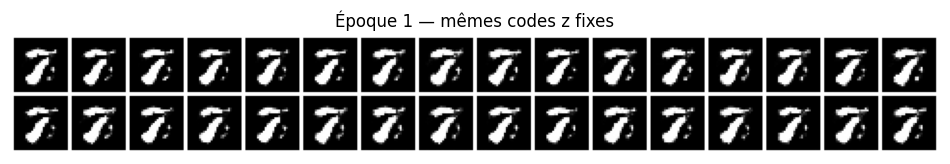

Époque  2/10 | loss_D = 1.068 | loss_G = 1.766 | 22 s


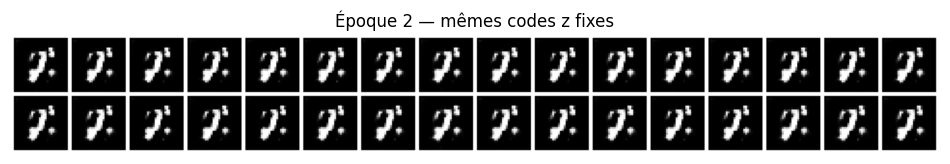

Époque  3/10 | loss_D = 0.888 | loss_G = 2.044 | 22 s


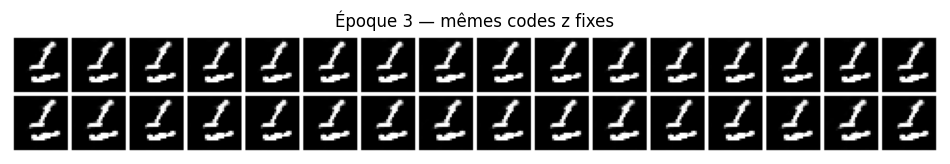

Époque  4/10 | loss_D = 0.856 | loss_G = 2.154 | 22 s


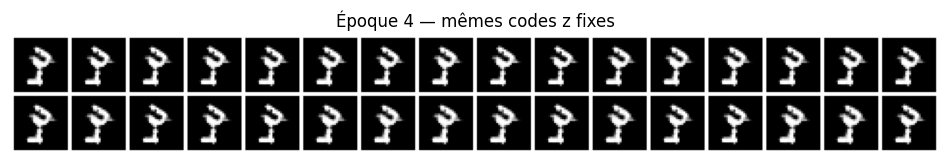

Époque  5/10 | loss_D = 0.626 | loss_G = 2.470 | 22 s


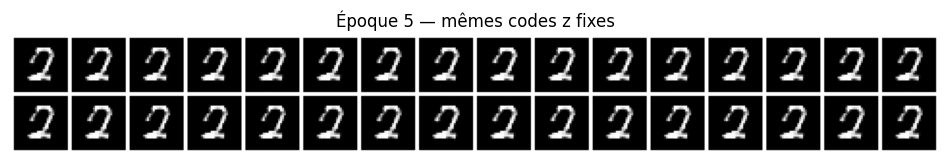

Époque  6/10 | loss_D = 0.500 | loss_G = 2.758 | 23 s


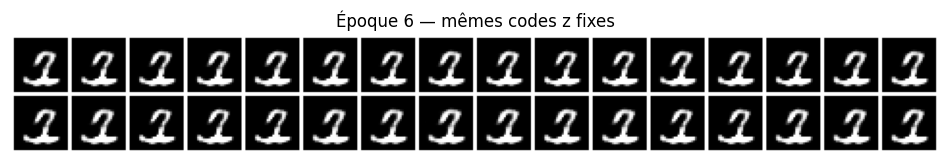

Époque  7/10 | loss_D = 0.453 | loss_G = 2.946 | 23 s


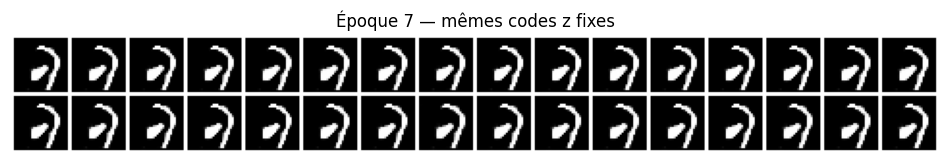

Époque  8/10 | loss_D = 0.438 | loss_G = 3.074 | 22 s


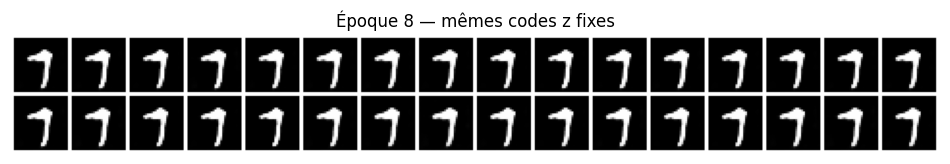

Époque  9/10 | loss_D = 0.351 | loss_G = 3.242 | 22 s


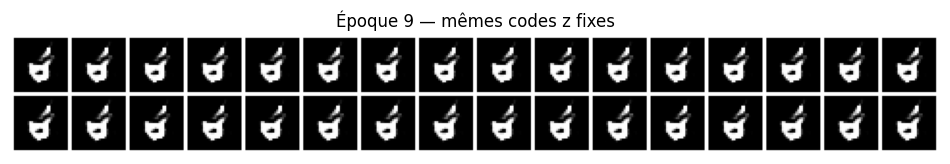

Époque 10/10 | loss_D = 0.301 | loss_G = 3.381 | 22 s


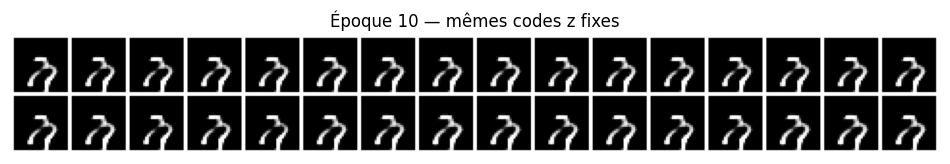

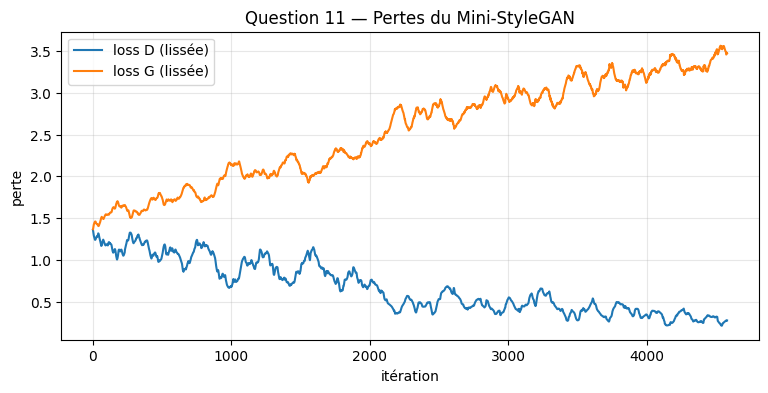

In [3]:
# =====================================================
# Partie D — Question 11 : boucle d'entraînement GAN (deux optimiseurs, entropie croisée binaire)
# =====================================================
import time
torch.manual_seed(0)
G = MiniStyleGAN().to(device)
D = Discriminateur().to(device)
opt_G = optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))   # optimiseur du générateur
opt_D = optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))   # optimiseur du discriminateur
bce = nn.BCELoss()

z_fixes = torch.randn(32, z_dim, device=device)    # codes latents FIXES pour suivre l'évolution (Q12)

def grille_fixe(titre):
    G.eval()
    with torch.no_grad():
        imgs = G(z_fixes).cpu()
    G.train()
    g = torchvision.utils.make_grid(imgs, nrow=16, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=(12, 1.8)); plt.imshow(g.permute(1, 2, 0)); plt.axis("off"); plt.title(titre); plt.show()

nb_epoques = 10
hist_D, hist_G = [], []                            # pertes par itération
for epoque in range(1, nb_epoques + 1):
    t0 = time.time(); sD = sG = 0.0
    for x_reel, _ in loader:
        b = x_reel.size(0)
        x_reel = x_reel.to(device)
        uns, zeros = torch.ones(b, 1, device=device), torch.zeros(b, 1, device=device)

        # style mixing pendant l'entraînement (1 fois sur 2) : apprend au générateur à combiner deux styles
        z1 = torch.randn(b, z_dim, device=device)
        if torch.rand(1).item() < 0.5:
            x_faux = G(z1, torch.randn(b, z_dim, device=device), croisement=np.random.randint(1, G.nb_styles))
        else:
            x_faux = G(z1)

        # pas du discriminateur : -[log D(x) + log(1 - D(G(z)))], detach() pour ne pas toucher G
        loss_D = bce(D(x_reel), uns) + bce(D(x_faux.detach()), zeros)
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()

        # pas du générateur : perte non saturante -log D(G(z))
        loss_G = bce(D(x_faux), uns)
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()

        hist_D.append(loss_D.item()); hist_G.append(loss_G.item())
        sD += loss_D.item(); sG += loss_G.item()
    print(f"Époque {epoque:2d}/{nb_epoques} | loss_D = {sD/len(loader):.3f} | loss_G = {sG/len(loader):.3f} | {time.time()-t0:.0f} s")

    # =====================================================
    # Partie D — Question 12 : grille d'images à partir des codes fixes, après chaque époque
    # =====================================================
    grille_fixe(f"Époque {epoque} — mêmes codes z fixes")

# ---- Courbes de pertes ----
def lisser(v, k=100):
    return np.convolve(v, np.ones(k) / k, mode="valid")
plt.figure(figsize=(9, 4))
plt.plot(lisser(hist_D), label="loss D (lissée)"); plt.plot(lisser(hist_G), label="loss G (lissée)")
plt.xlabel("itération"); plt.ylabel("perte"); plt.title("Question 11 — Pertes du Mini-StyleGAN")
plt.legend(); plt.grid(alpha=0.3); plt.show()

In [4]:
# =====================================================
# Question 11-12 — Premier essai : observation d'un effondrement de modes (mode collapse)
# =====================================================
# Avec ce premier discriminateur, l'entraînement échoue : les 32 codes z fixes donnent tous EXACTEMENT
# la même image (un « 2 » à l'époque 5, une autre forme unique à l'époque 10). Le générateur a trouvé une
# seule image qui trompe le discriminateur et ignore complètement z. Le discriminateur apprend ensuite à
# rejeter cette image, le générateur change de forme sans retrouver de diversité, et D domine de plus en
# plus (loss_D : 1,23 -> 0,30 ; loss_G : 1,54 -> 3,38).
# Cause : D juge chaque image séparément, il ne peut donc pas voir que toutes les images d'un batch se
# ressemblent ; de plus, la BatchNorm dans D (batchs séparés de vraies et de fausses images) est connue
# pour déstabiliser l'entraînement.
# Corrections (inspirées de StyleGAN / ProGAN) :
#   1. couche « minibatch standard deviation » dans D : D reçoit la diversité du batch et peut pénaliser
#      un générateur qui produit toujours la même image ;
#   2. suppression de la BatchNorm dans D ;
#   3. lissage des étiquettes (cible 0,9 au lieu de 1 pour les vraies images) pour freiner D.
print("Mode collapse documenté.")

Mode collapse documenté.


Époque  1/10 | loss_D = 1.225 | loss_G = 1.156 | diversité = 0.278 | 25 s


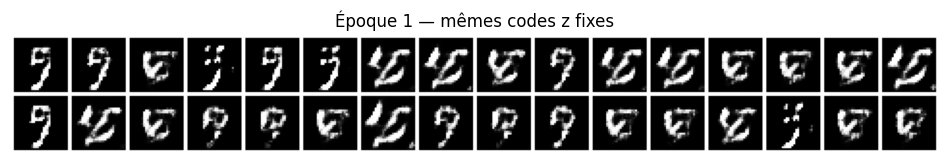

Époque  2/10 | loss_D = 1.228 | loss_G = 1.083 | diversité = 0.348 | 24 s


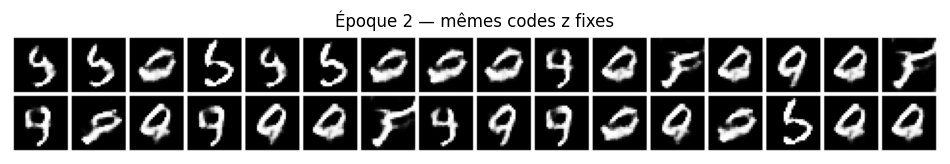

Époque  3/10 | loss_D = 1.235 | loss_G = 1.058 | diversité = 0.371 | 24 s


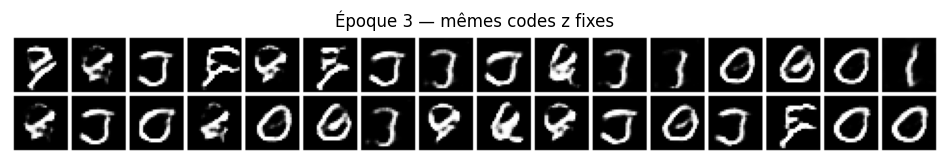

Époque  4/10 | loss_D = 1.204 | loss_G = 1.125 | diversité = 0.368 | 24 s


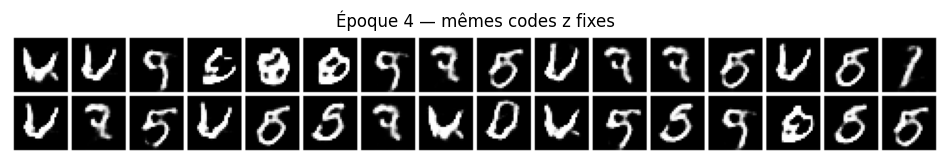

Époque  5/10 | loss_D = 1.152 | loss_G = 1.262 | diversité = 0.374 | 24 s


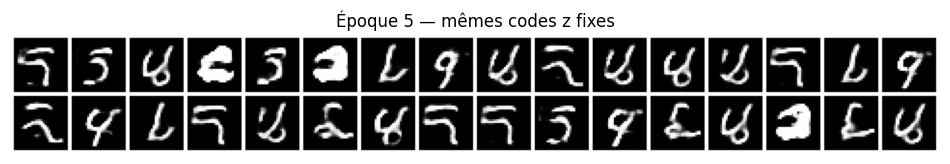

Époque  6/10 | loss_D = 1.115 | loss_G = 1.339 | diversité = 0.393 | 24 s


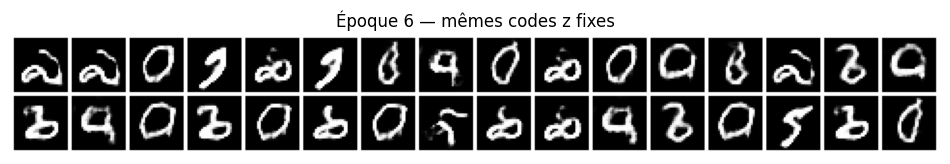

Époque  7/10 | loss_D = 1.149 | loss_G = 1.298 | diversité = 0.394 | 24 s


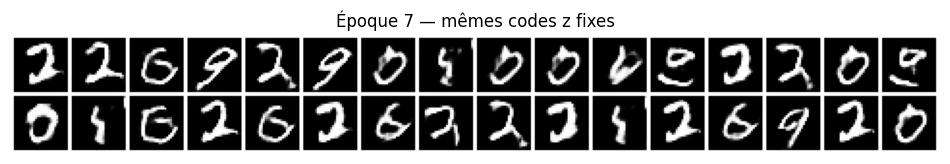

Époque  8/10 | loss_D = 1.110 | loss_G = 1.384 | diversité = 0.382 | 24 s


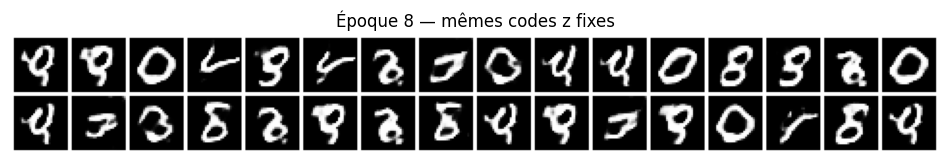

Époque  9/10 | loss_D = 1.078 | loss_G = 1.443 | diversité = 0.377 | 24 s


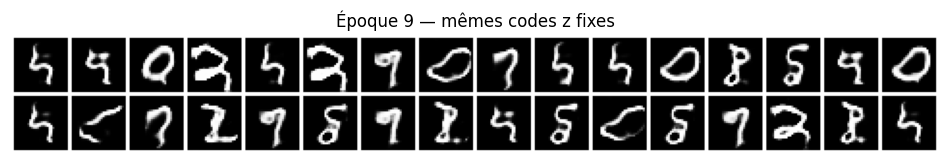

Époque 10/10 | loss_D = 1.097 | loss_G = 1.407 | diversité = 0.379 | 24 s


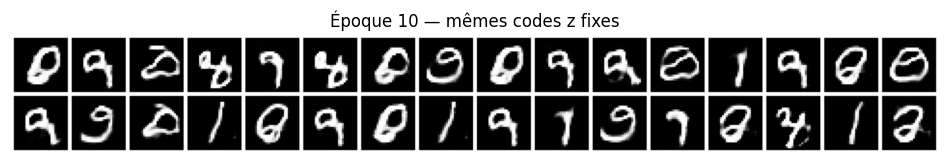

Diversité de 32 vraies images (référence) : 0.346


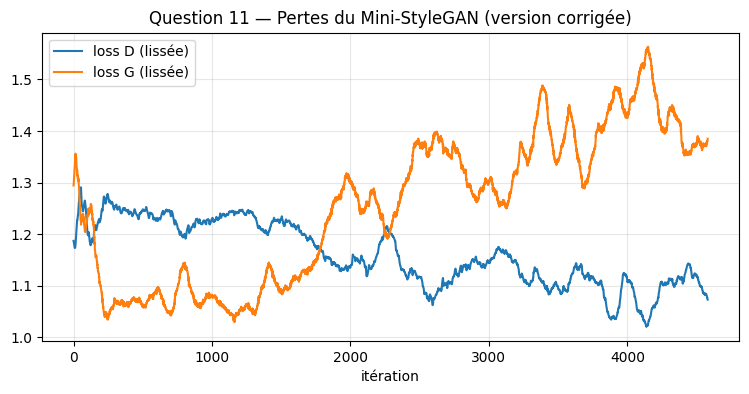

In [5]:
# =====================================================
# Question 10 (version corrigée) — Discriminateur avec couche « minibatch standard deviation », sans BatchNorm
# =====================================================
class Discriminateur(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(1, 64, 4, 2, 1), nn.LeakyReLU(0.2),        # -> 64x14x14
            nn.Conv2d(64, 128, 4, 2, 1), nn.LeakyReLU(0.2))      # -> 128x7x7
        self.fin = nn.Sequential(
            nn.Conv2d(128 + 1, 128, 3, padding=1), nn.LeakyReLU(0.2),   # +1 canal : diversité du batch
            nn.Flatten(), nn.Linear(128 * 7 * 7, 1), nn.Sigmoid())
    def forward(self, x):
        h = self.conv(x)
        diversite = h.std(dim=0).mean()                           # écart-type entre les images du batch
        carte = diversite.view(1, 1, 1, 1).expand(h.size(0), 1, h.size(2), h.size(3))
        return self.fin(torch.cat([h, carte], dim=1))            # D « voit » si le batch est varié

# =====================================================
# Question 11 — Boucle d'entraînement (deux optimiseurs, BCE, lissage des étiquettes)
# =====================================================
torch.manual_seed(0)
G = MiniStyleGAN().to(device)
D = Discriminateur().to(device)
opt_G = optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCELoss()
z_fixes = torch.randn(32, z_dim, device=device)

def diversite_images(imgs):                      # indicateur de diversité : 0 si toutes les images sont identiques
    return imgs.std(dim=0).mean().item()

nb_epoques = 10
hist_D, hist_G = [], []
for epoque in range(1, nb_epoques + 1):
    t0 = time.time(); sD = sG = 0.0
    for x_reel, _ in loader:
        b = x_reel.size(0)
        x_reel = x_reel.to(device)
        cible_reel = torch.full((b, 1), 0.9, device=device)        # lissage des étiquettes : 0,9 au lieu de 1
        uns, zeros = torch.ones(b, 1, device=device), torch.zeros(b, 1, device=device)
        z1 = torch.randn(b, z_dim, device=device)
        if torch.rand(1).item() < 0.5:                              # style mixing pendant l'entraînement
            x_faux = G(z1, torch.randn(b, z_dim, device=device), croisement=np.random.randint(1, G.nb_styles))
        else:
            x_faux = G(z1)
        loss_D = bce(D(x_reel), cible_reel) + bce(D(x_faux.detach()), zeros)   # pas de D
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()
        loss_G = bce(D(x_faux), uns)                                            # pas de G (non saturant)
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()
        hist_D.append(loss_D.item()); hist_G.append(loss_G.item())
        sD += loss_D.item(); sG += loss_G.item()

    # =====================================================
    # Question 12 — Grille à partir des codes fixes après chaque époque
    # =====================================================
    G.eval()
    with torch.no_grad():
        imgs = G(z_fixes).cpu()
    G.train()
    print(f"Époque {epoque:2d}/{nb_epoques} | loss_D = {sD/len(loader):.3f} | loss_G = {sG/len(loader):.3f} "
          f"| diversité = {diversite_images(imgs):.3f} | {time.time()-t0:.0f} s")
    g = torchvision.utils.make_grid(imgs, nrow=16, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=(12, 1.8)); plt.imshow(g.permute(1, 2, 0)); plt.axis("off")
    plt.title(f"Époque {epoque} — mêmes codes z fixes"); plt.show()

x_vrais, _ = next(iter(loader))
print(f"Diversité de 32 vraies images (référence) : {diversite_images(x_vrais[:32]):.3f}")

lisser = lambda v, k=100: np.convolve(v, np.ones(k) / k, mode="valid")
plt.figure(figsize=(9, 4))
plt.plot(lisser(hist_D), label="loss D (lissée)"); plt.plot(lisser(hist_G), label="loss G (lissée)")
plt.xlabel("itération"); plt.title("Question 11 — Pertes du Mini-StyleGAN (version corrigée)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

Q13 | ψ = 0.00 | diversité = 0.000
Q13 | ψ = 0.25 | diversité = 0.202
Q13 | ψ = 0.50 | diversité = 0.267
Q13 | ψ = 0.75 | diversité = 0.308
Q13 | ψ = 1.00 | diversité = 0.325
Q13 | ψ = 1.50 | diversité = 0.336


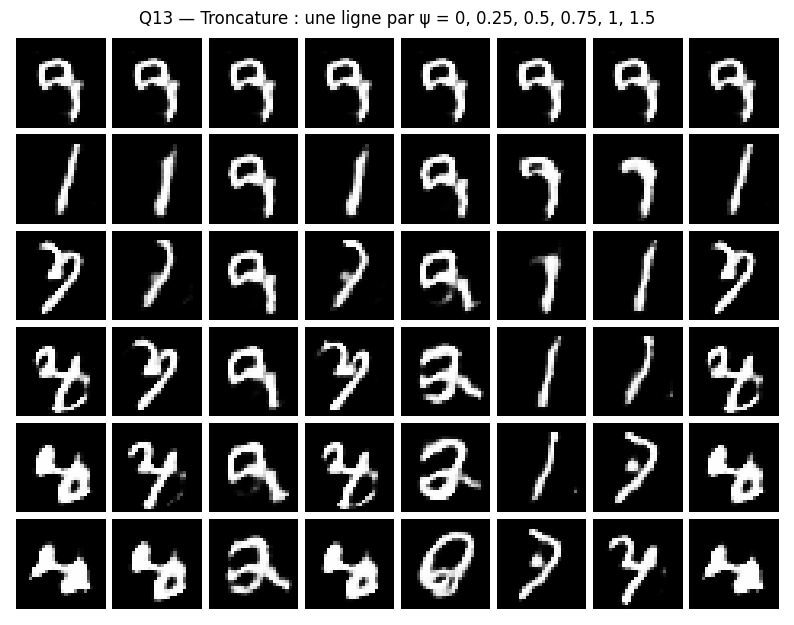

Q14 | interpolation dans Z : écart moyen = 0.516 | écart max = 0.827 | max/moyen = 1.60  (proche de 1 = transition régulière)
Q14 | interpolation dans W : écart moyen = 0.586 | écart max = 0.854 | max/moyen = 1.46  (proche de 1 = transition régulière)


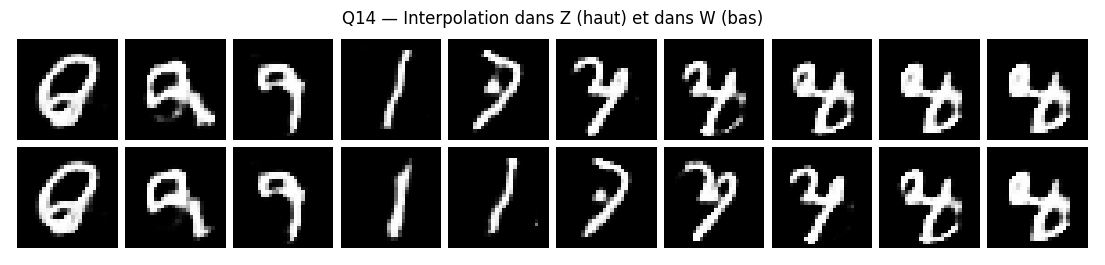

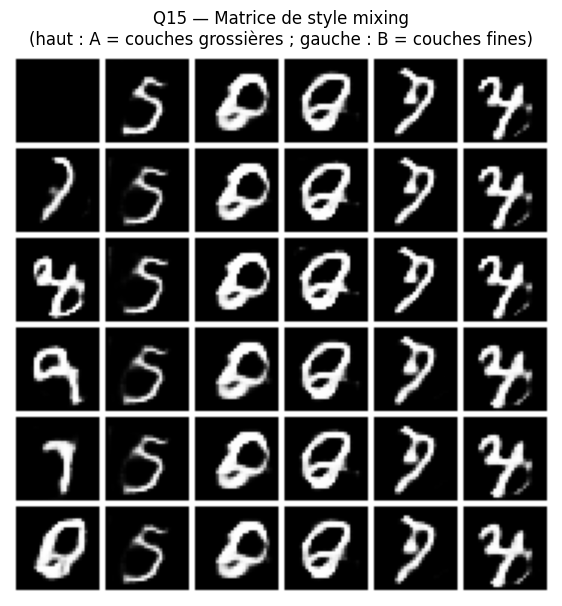

Q16 | variation due au bruit seul (même z)  : 0.0032
Q16 | variation due à z (même bruit)        : 0.3900
Q16 | |α| moyen appris par bloc (7x7, 14x14, 28x28, 28x28) : [0.055, 0.005, 0.001, 0.008]


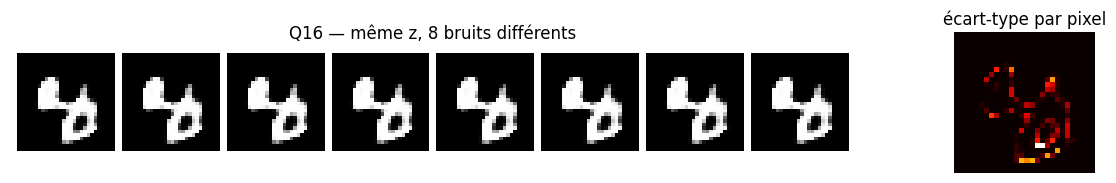

Q17 | précision du classifieur sur 2000 vraies images : 97.3 %


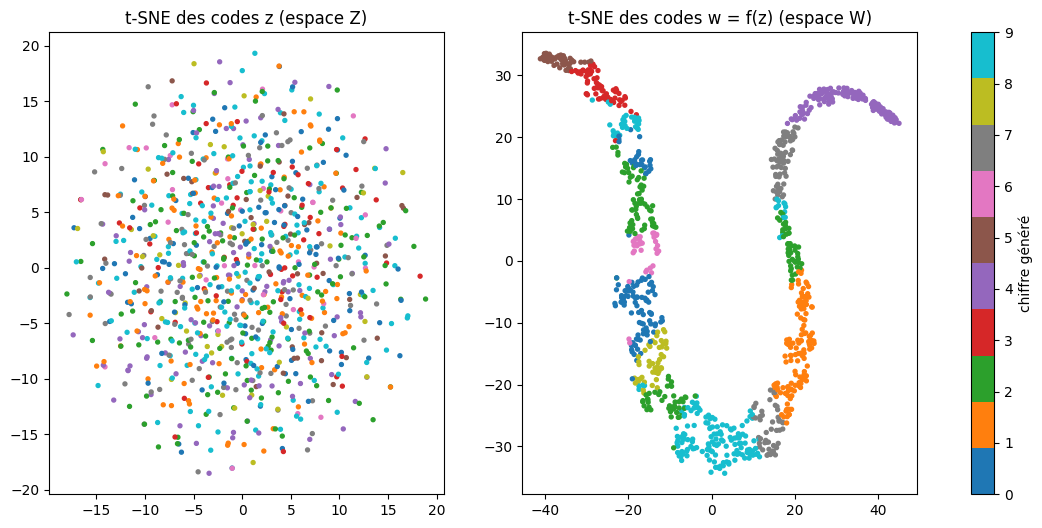

Q17 | nombre d'images générées par chiffre : [114 125 154  63 118  45  36 112  47 186]


In [6]:
# =====================================================
# Partie E — Outils communs
# =====================================================
from sklearn.manifold import TSNE
G.eval()
n_blocs = G.nb_styles
tailles = [7, 14, 28, 28]                          # taille des cartes de chaque bloc stylisé

def bruits_fixes(n, graine=0):                     # même bruit pour toutes les images (pour isoler l'effet de z ou w)
    gen = torch.Generator().manual_seed(graine)
    return [torch.randn(1, 1, s, s, generator=gen).expand(n, 1, s, s).to(device) for s in tailles]

def montrer(imgs, nrow, titre, figsize):
    g = torchvision.utils.make_grid(imgs.cpu(), nrow=nrow, normalize=True, value_range=(-1, 1), pad_value=1)
    plt.figure(figsize=figsize); plt.imshow(g.permute(1, 2, 0)); plt.axis("off"); plt.title(titre); plt.show()

# =====================================================
# Question 13 — Troncature : w_ψ = w̄ + ψ (w - w̄)
# =====================================================
with torch.no_grad():
    w_moyen = G.mapping(torch.randn(10000, z_dim, device=device)).mean(0, keepdim=True)   # moyenne empirique w̄
    torch.manual_seed(1)
    w13 = G.mapping(torch.randn(8, z_dim, device=device))
    psis = [0, 0.25, 0.5, 0.75, 1.0, 1.5]
    lignes = []
    for psi in psis:
        imgs = G.synthese([w_moyen + psi * (w13 - w_moyen)] * n_blocs, bruits_fixes(8))
        lignes.append(imgs)
        print(f"Q13 | ψ = {psi:4.2f} | diversité = {diversite_images(imgs.cpu()):.3f}")
montrer(torch.cat(lignes), 8, "Q13 — Troncature : une ligne par ψ = 0, 0.25, 0.5, 0.75, 1, 1.5", (10, 8))

# =====================================================
# Question 14 — Interpolation linéaire dans Z et dans W
# =====================================================
torch.manual_seed(2)
za, zb = torch.randn(1, z_dim, device=device), torch.randn(1, z_dim, device=device)
ts = torch.linspace(0, 1, 10, device=device)
with torch.no_grad():
    z_interp = torch.cat([(1 - t) * za + t * zb for t in ts])                       # chemin droit dans Z
    w_a, w_b = G.mapping(za), G.mapping(zb)
    w_interp = torch.cat([(1 - t) * w_a + t * w_b for t in ts])                     # chemin droit dans W
    bf = bruits_fixes(len(ts))
    img_Z = G.synthese([G.mapping(z_interp)] * n_blocs, bf)
    img_W = G.synthese([w_interp] * n_blocs, bf)
for nom, imgs in [("Z", img_Z), ("W", img_W)]:
    d = (imgs[1:] - imgs[:-1]).pow(2).mean(dim=(1, 2, 3)).sqrt()                    # écart entre images voisines
    print(f"Q14 | interpolation dans {nom} : écart moyen = {d.mean().item():.3f} | écart max = {d.max().item():.3f} "
          f"| max/moyen = {(d.max() / d.mean()).item():.2f}  (proche de 1 = transition régulière)")
montrer(torch.cat([img_Z, img_W]), 10, "Q14 — Interpolation dans Z (haut) et dans W (bas)", (14, 3.2))

# =====================================================
# Question 15 — Style mixing : couches grossières de z_A, couches fines de z_B
# =====================================================
torch.manual_seed(3)
nA = nB = 5
zA, zB = torch.randn(nA, z_dim, device=device), torch.randn(nB, z_dim, device=device)
with torch.no_grad():
    wA, wB = G.mapping(zA), G.mapping(zB)
    imgA = G.synthese([wA] * n_blocs, bruits_fixes(nA))
    imgB = G.synthese([wB] * n_blocs, bruits_fixes(nB))
    cases = [-torch.ones(1, 1, 28, 28, device=device)] + [imgA[j:j + 1] for j in range(nA)]   # 1re ligne : sources A
    for i in range(nB):
        cases.append(imgB[i:i + 1])                                                        # 1re colonne : sources B
        for j in range(nA):
            ws = [wA[j:j + 1]] * 2 + [wB[i:i + 1]] * (n_blocs - 2)                         # 2 blocs grossiers A, 2 blocs fins B
            cases.append(G.synthese(ws, bruits_fixes(1)))
montrer(torch.cat(cases), nA + 1, "Q15 — Matrice de style mixing\n(haut : A = couches grossières ; gauche : B = couches fines)", (7, 7.5))

# =====================================================
# Question 16 — Rôle du bruit stochastique : même z, bruits différents
# =====================================================
torch.manual_seed(4)
with torch.no_grad():
    w16 = G.mapping(torch.randn(1, z_dim, device=device).repeat(8, 1))   # 8 fois le MÊME code
    imgs16 = G.synthese([w16] * n_blocs)                                 # bruit aléatoire différent pour chaque image
    imgs_z = G.synthese([G.mapping(torch.randn(8, z_dim, device=device))] * n_blocs, bruits_fixes(8))
print(f"Q16 | variation due au bruit seul (même z)  : {diversite_images(imgs16.cpu()):.4f}")
print(f"Q16 | variation due à z (même bruit)        : {diversite_images(imgs_z.cpu()):.4f}")
print("Q16 | |α| moyen appris par bloc (7x7, 14x14, 28x28, 28x28) :",
      [round(b.bruit.alpha.abs().mean().item(), 3) for b in G.blocs])
fig, ax = plt.subplots(1, 2, figsize=(14, 2.6), gridspec_kw={"width_ratios": [6, 1]})
g = torchvision.utils.make_grid(imgs16.cpu(), nrow=8, normalize=True, value_range=(-1, 1), pad_value=1)
ax[0].imshow(g.permute(1, 2, 0)); ax[0].axis("off"); ax[0].set_title("Q16 — même z, 8 bruits différents")
ax[1].imshow(imgs16.std(0).squeeze().cpu(), cmap="hot"); ax[1].axis("off"); ax[1].set_title("écart-type par pixel")
plt.show()

# =====================================================
# Question 17 — Projection t-SNE sécurisée de z et de w = f(z)
# (peu de points, n_jobs=1 pour limiter les threads)
# =====================================================
clf = nn.Sequential(                                # petit classifieur pour colorer les points par chiffre
    nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
    nn.Flatten(), nn.Linear(64 * 7 * 7, 10)).to(device)
opt_c = optim.Adam(clf.parameters(), lr=1e-3)
for x, y in loader:                                 # 1 époque suffit (~98 %)
    perte = F.cross_entropy(clf(x.to(device)), y.to(device))
    opt_c.zero_grad(); perte.backward(); opt_c.step()
clf.eval()
test_set = torchvision.datasets.MNIST(root="./data", train=False, download=True, transform=transform)
xt, yt = test_set.data[:2000].float().div(127.5).sub(1).unsqueeze(1), test_set.targets[:2000]
with torch.no_grad():
    print(f"Q17 | précision du classifieur sur 2000 vraies images : {100 * (clf(xt.to(device)).argmax(1).cpu() == yt).float().mean():.1f} %")

n_pts = 1000
torch.manual_seed(5)
z17 = torch.randn(n_pts, z_dim, device=device)
with torch.no_grad():
    w17 = G.mapping(z17)
    classes17 = clf(G.synthese([w17] * n_blocs, bruits_fixes(n_pts))).argmax(1).cpu().numpy()
z_2d = TSNE(n_components=2, perplexity=30, init="pca", random_state=0, n_jobs=1).fit_transform(z17.cpu().numpy())
w_2d = TSNE(n_components=2, perplexity=30, init="pca", random_state=0, n_jobs=1).fit_transform(w17.cpu().numpy())
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, P, titre in zip(ax, [z_2d, w_2d], ["t-SNE des codes z (espace Z)", "t-SNE des codes w = f(z) (espace W)"]):
    nuage = a.scatter(P[:, 0], P[:, 1], c=classes17, cmap="tab10", s=8, vmin=0, vmax=9); a.set_title(titre)
fig.colorbar(nuage, ax=ax, ticks=range(10), label="chiffre généré")
plt.show()
print("Q17 | nombre d'images générées par chiffre :", np.bincount(classes17, minlength=10))

In [8]:
# =====================================================
# Question 12 — Commentaire : évolution qualitative des images
# =====================================================
# Premier essai : effondrement de modes complet (les 32 codes fixes donnent la même image, D domine).
# Version corrigée (couche minibatch-std dans D, sans BatchNorm, lissage des étiquettes) : dès l'époque 1,
# les images sont des formes floues mais déjà différentes d'un code à l'autre ; au fil des époques, les
# traits deviennent plus nets et les chiffres lisibles et variés. La diversité des images générées passe
# de 0,278 (époque 1) à 0,379 (époque 10), comparable à celle de vraies images (0,346), et les pertes
# restent équilibrées (loss_D ≈ 1,10, loss_G ≈ 1,41) : il n'y a plus d'effondrement de modes.

# =====================================================
# Question 13 — Commentaire : effet de la troncature ψ
# =====================================================
# Avec ψ = 0, tous les codes sont remplacés par w̄ : toutes les images sont identiques (diversité 0,000),
# c'est l'image « moyenne » du modèle. Quand ψ augmente, la diversité croît (0,202 pour ψ = 0,25 ; 0,325
# pour ψ = 1 ; 0,336 pour ψ = 1,5). Un petit ψ rapproche les codes du centre de W, région bien apprise :
# images plus propres et plus « typiques », mais peu variées. Un grand ψ (> 1) éloigne les codes vers des
# zones rares de W : plus de diversité, mais plus de risque de formes déformées.
# Observé sur la figure : pour ψ = 1,5, plusieurs images deviennent des taches ou des formes illisibles.
# La troncature règle donc le compromis qualité / diversité.

# =====================================================
# Question 14 — Commentaire : interpolation dans Z et dans W
# =====================================================
# On mesure l'écart entre deux images voisines le long du chemin. Dans Z, le rapport écart max / écart
# moyen vaut 1,60 ; dans W, il vaut 1,46 : la transformation est un peu mieux répartie dans W, avec moins
# de « sauts » brusques. L'interpolation dans W semble donc légèrement plus régulière, ce qui est cohérent
# avec l'idée que W est plus « démêlé » que Z. L'écart reste modeste sur ce petit modèle entraîné
# 10 époques ; sur les vrais StyleGAN, la différence est beaucoup plus nette (mesurée par le
# « perceptual path length »).

# =====================================================
# Question 15 — Commentaire : matrice de style mixing
# =====================================================
# Chaque case combine les styles de z_A pour les deux blocs grossiers (7x7 et 14x14) et ceux de z_B pour
# les deux blocs fins (28x28). On observe que chaque colonne reproduit presque exactement l'image A du haut
# (même chiffre, même forme, même inclinaison), quel que soit le code B de la ligne : les couches fines ne
# modifient que de légers détails (épaisseur et netteté du trait). Dans notre Mini-StyleGAN, les couches
# grossières déterminent donc l'essentiel de l'image. C'est cohérent avec le principe de StyleGAN (les
# basses résolutions fixent la structure globale), mais l'effet des couches fines est ici très faible :
# des images 28x28 de chiffres contiennent peu de détails fins, et la structure du chiffre est déjà
# entièrement fixée à la résolution 14x14. Sur des visages en haute résolution, les couches fines
# contrôleraient des attributs visibles comme la couleur ou la texture.

# =====================================================
# Question 16 — Commentaire : rôle du bruit stochastique
# =====================================================
# Avec le même z et des bruits différents, les images sont presque identiques : la variation due au bruit
# (0,0032) est environ 120 fois plus faible que celle due à z (0,390). L'identité du chiffre, sa forme et
# son style restent stables ; seuls de minuscules détails locaux du trait varient (visibles sur la carte
# d'écart-type). Le modèle a appris des poids de bruit très faibles (|α| entre 0,001 et 0,055) : sur MNIST,
# il n'y a presque pas de détails stochastiques à modéliser (pas de cheveux ni de textures), donc le
# générateur utilise très peu le bruit.

# =====================================================
# Question 17 — Commentaire : projection t-SNE de Z et de W
# =====================================================
# Le t-SNE est calculé sur 1000 points seulement, avec n_jobs=1, pour éviter les blocages. Les points sont
# colorés par le chiffre généré (classifieur à 97,3 % sur de vraies images).
# Dans Z (gaussienne isotrope), on obtient un nuage rond où toutes les classes sont mélangées : la position
# dans Z ne dit rien du chiffre généré. Dans W, les codes forment deux longues bandes continues, et chaque
# chiffre occupe un segment bien délimité (par exemple 5, 3, 9, 2, 0, 8 sur la première bande ; 4, 7, 2, 1
# sur la seconde). Le réseau de mapping a donc réorganisé l'espace latent : W est beaucoup plus structuré
# sémantiquement que Z, et des chiffres voisins dans W sont souvent visuellement proches (comme 3 et 5, ou
# 4, 7 et 9). On remarque aussi que W se concentre sur des structures de faible dimension : le mapping
# exploite seulement une petite partie de ses 64 dimensions.

# =====================================================
# Partie F — Question 18 : lien avec StyleGAN2
# =====================================================
# Convolution modulée/démodulée : AdaIN normalise les activations et crée des artefacts en forme de
# « gouttes ». StyleGAN2 applique le style directement aux POIDS de la convolution : modulation
# w'_ijk = s_i · w_ijk (s = style issu de w), puis démodulation w''_ijk = w'_ijk / sqrt(Σ w'_ijk² + ε),
# qui ramène la variance des sorties à 1. On obtient le même contrôle du style sans normaliser
# explicitement les activations, ce qui supprime les artefacts.
# Régularisation de longueur de chemin (path length) : on pénalise les variations de la norme de
# ‖J_w^T y‖ (J_w = jacobien de G par rapport à w, y = image aléatoire) autour d'une valeur moyenne.
# Un petit déplacement fixe dans W produit ainsi un changement d'image de taille constante : l'espace W
# est plus lisse, les interpolations plus régulières et l'inversion d'images plus facile.

# =====================================================
# Partie F — Question 19 : limites de l'expérience
# =====================================================
# 1. Données : MNIST, images 28x28 en niveaux de gris, contre 1024x1024 en couleur pour FFHQ ou LSUN.
# 2. Taille du modèle : environ 0,3 million de paramètres et 4 blocs, contre environ 30 millions de
#    paramètres et 18 couches de style pour StyleGAN.
# 3. Durée d'entraînement : 10 époques (environ 4 minutes sur un GPU T4), contre plusieurs jours ou
#    semaines sur plusieurs GPU haut de gamme.
# 4. Techniques absentes : croissance progressive / architecture à sauts, taux d'apprentissage égalisé,
#    taux d'apprentissage réduit pour le mapping, régularisation R1, path length, augmentation de
#    données adaptative (ADA), modulation/démodulation.
# 5. Perte simple (BCE) et instabilités observées (effondrement de modes au premier essai).
# 6. Évaluation uniquement visuelle et par un indicateur simple de diversité, sans métrique comme la FID.

# =====================================================
# Partie F — Question 20 : conclusion
# =====================================================
# Concepts appris : différence entre un GAN classique (z en entrée) et un générateur style-based
# (mapping z -> w, constante apprise, injection du style à chaque résolution par AdaIN, bruit
# stochastique) ; rôle des espaces Z et W ; troncature, style mixing et interpolation ; difficultés de
# l'entraînement adversarial (effondrement de modes).
# Résultats obtenus : un Mini-StyleGAN de 0,3 million de paramètres entraîné sur MNIST. Un premier essai
# a montré un effondrement de modes complet ; l'ajout d'une couche minibatch-std, la suppression de la
# BatchNorm et le lissage des étiquettes ont corrigé le problème (diversité 0,379 contre 0,346 pour de
# vraies images, pertes équilibrées). La troncature règle le compromis qualité/diversité, l'interpolation
# est légèrement plus régulière dans W que dans Z (1,46 contre 1,60), W est nettement organisé par
# chiffre contrairement à Z, les couches grossières déterminent l'essentiel de l'image, et le bruit n'a
# qu'un effet minime sur MNIST.
# Améliorations possibles : entraîner plus longtemps ; utiliser Fashion-MNIST ou une résolution plus
# élevée avec plus de blocs ; convolutions modulées/démodulées (StyleGAN2), taux d'apprentissage égalisé
# et réduit pour le mapping, régularisation R1 et path length ; perte hinge ; évaluation par FID.
print("TP 4 (StyleGAN) complet : questions 1 à 20.")

TP 4 (StyleGAN) complet : questions 1 à 20.
